In [1]:
import numpy as np

from data import *
from catalogs import *
from interactive import *
from util import *
from preprocessing import *
from postprocessing import *
import astropy.wcs as wcs

from flow import Flow

from matplotlib import rc
import matplotlib.pylab as plt

rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})
rc('text', usetex=True)

%matplotlib widget

%load_ext autoreload
%autoreload 2

In [26]:
# Note: the timing is slow the first time as JAX compiles the GPU kernels,
# but it becomes much faster once re-run
%time image, psf, imwcs = data_1hour(30, order="freq")
%time sky = theoretical_sky(imwcs, psf, catalog="VLSSR", max_flux=10)
%time image_processed, sky_processed = preprocess(image, sky, weight=1.5)
%time flow = Flow.brox(image_processed, sky_processed, alpha=1.0, gamma=150, scale_factor=0.7)

CPU times: user 54.4 ms, sys: 18.1 ms, total: 72.5 ms
Wall time: 71.4 ms
CPU times: user 81.8 ms, sys: 6.24 ms, total: 88 ms
Wall time: 76.8 ms
CPU times: user 19.8 ms, sys: 2.23 ms, total: 22 ms
Wall time: 137 ms
CPU times: user 44.1 ms, sys: 46.9 ms, total: 91 ms
Wall time: 90.9 ms


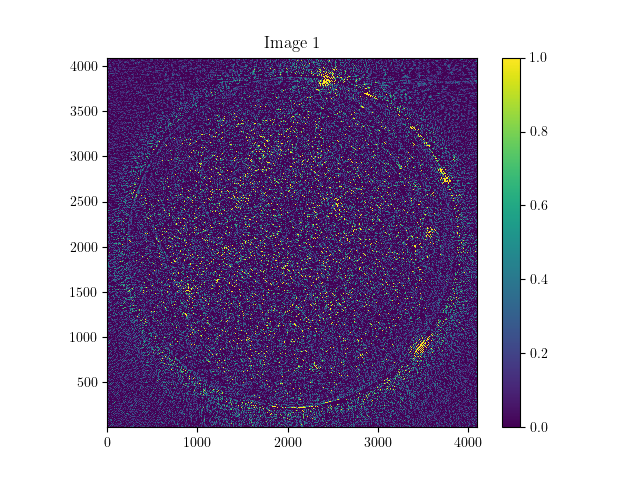

In [3]:
toggle_images(normalize_high(image), normalize_high(sky), name="inputs")

In [6]:
XLIM = (2250, 2450)
YLIM = (1550, 1750)

XLIMQ = (150, 4096-150)
YLIMQ = (150, 4096-150)

## Showing PSF

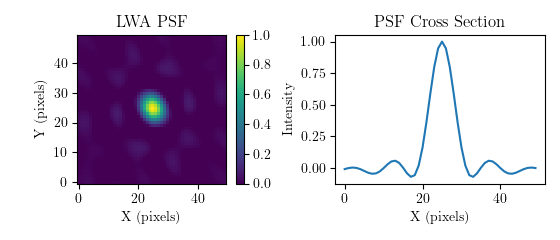

In [7]:
import matplotlib.gridspec as gridspec

w = 25

psf_center = psf[4096//2 - w:4096//2 + w, 4096//2 - w:4096//2 + w]

# plot_image(psf_center)

plt.close("psf_cross")
fig = plt.figure(figsize=(7*0.8, 3*0.8), num="psf_cross")

# Create a GridSpec layout
# 1 row, 2 columns, with a width ratio of 2:1
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1])

# Add subplots to the GridSpec
ax2 = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[1])

ax1.plot(psf[4096//2, 4096//2-w:4096//2+w])
mat = ax2.imshow(psf_center, cmap='viridis', vmin=0, vmax=1, interpolation="nearest", origin="lower",)

ax1.set_title("PSF Cross Section")
ax1.set_xlabel("X (pixels)")
ax1.set_ylabel("Intensity")
ax2.set_title("LWA PSF")
ax2.set_xlabel("X (pixels)")
ax2.set_ylabel("Y (pixels)")

fig.colorbar(mat)

plt.tight_layout()
plt.show()

plt.savefig("psf.png", dpi=300)

## Showing Preprocessing

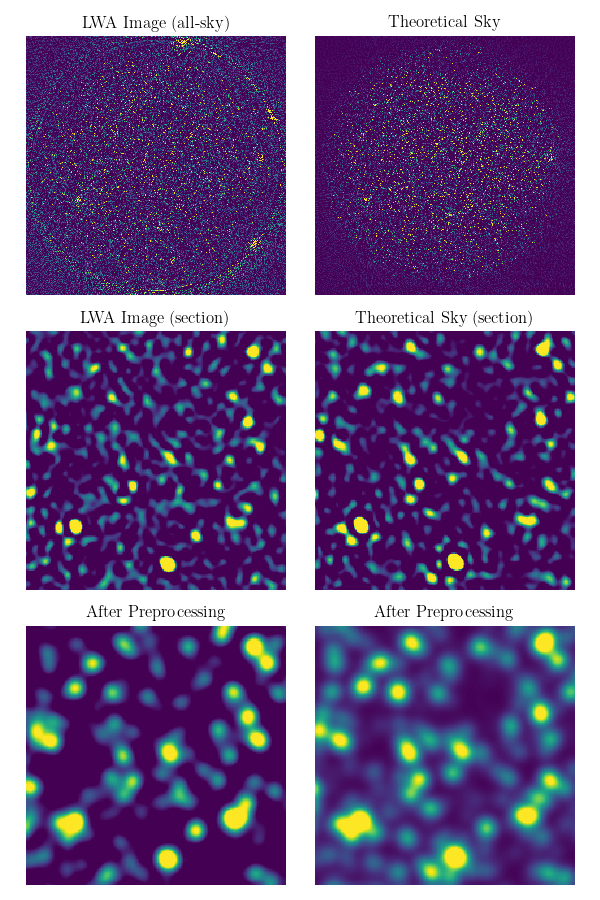

In [8]:
images = [
    normalize_high(image)[XLIMQ[0]:XLIMQ[1], YLIMQ[0]:YLIMQ[1]],
    normalize_high(sky)[XLIMQ[0]:XLIMQ[1], YLIMQ[0]:YLIMQ[1]],
    normalize_high(image)[XLIM[0]:XLIM[1], YLIM[0]:YLIM[1]],
    normalize_high(sky)[XLIM[0]:XLIM[1], YLIM[0]:YLIM[1]],
    normalize_high(image_processed[XLIM[0]:XLIM[1], YLIM[0]:YLIM[1]]),
    normalize_high(sky_processed)[XLIM[0]:XLIM[1], YLIM[0]:YLIM[1]],
]
titles = ['LWA Image (all-sky)', 'Theoretical Sky',
            'LWA Image (section)',
            'Theoretical Sky (section)',
              'After Preprocessing', 'After Preprocessing']

plt.close("preprocessing")
fig, axes = plt.subplots(3, 2, figsize=(6, 9), num="preprocessing")

for ax, img, title in zip(axes.ravel(), images, titles):
    ax.imshow(img, cmap='viridis', vmin=0, vmax=1, interpolation="nearest", origin="lower",)
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

plt.savefig('preprocessing.png', format='png', dpi=300)

## Showing effect of dewarping

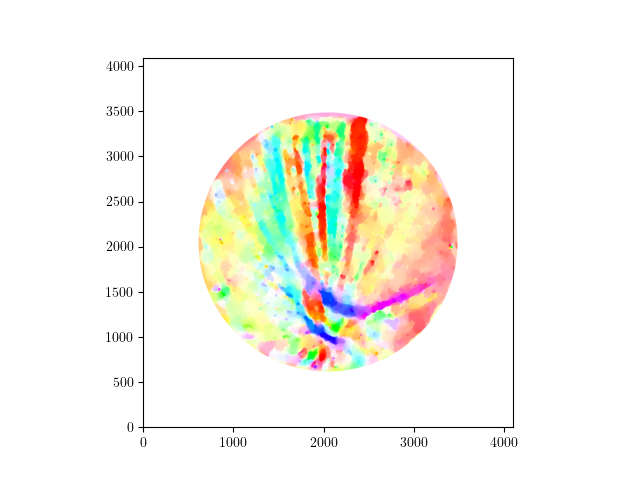

In [9]:
plot_flow(flow, scale=5, mask=circular_mask(r=0.7), name="flow")

In [10]:
positions, fluxes = reference_sources(catalog="VLSSR")

positions_xy = jnp.stack(wcs.utils.skycoord_to_pixel(positions, imwcs), axis=1)

# filter out NaNs, e.g. sources not in the field of view
ignore_positions = jnp.isnan(positions_xy).any(axis=1)
positions_xy = positions_xy[~ignore_positions & (fluxes > 0.10)]

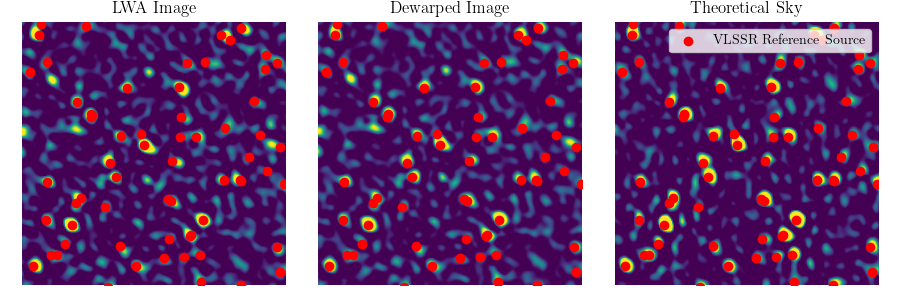

In [11]:
images = [
    normalize_high(image),
    flow.apply(normalize_high(image)),
    normalize_high(sky),
]
titles = ["LWA Image", "Dewarped Image", "Theoretical Sky"]

plt.close("dewarping")
fig, axes = plt.subplots(1, 3, figsize=(9, 3), num="dewarping")

for ax, img, title in zip(axes.ravel(), images, titles):
    ax.imshow(img, cmap='viridis', vmin=0, vmax=1, interpolation="bilinear", origin="lower",)
    ax.scatter(positions_xy[:, 0], positions_xy[:, 1], color="r", label="VLSSR Reference Source")
    ax.set_xlim(*XLIM)
    ax.set_ylim(*YLIM)
    ax.set_title(title)
    ax.axis('off')

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

plt.savefig('dewarping.png', format='png', dpi=300)

## Showing circular calibration effect

In [12]:
flow_components = rotational_translational_component(
    jnp.array([1500, 2000]),
    flow.offsets,
    circular_mask(r=0.7)
)

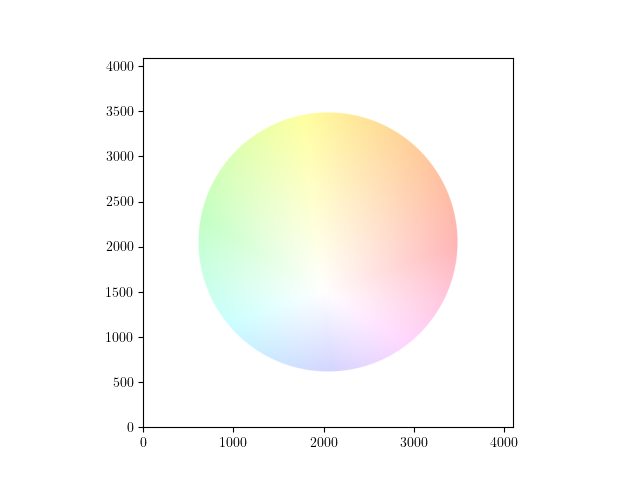

In [13]:
plot_flow(flow_components, scale=5, mask=circular_mask(r=0.7), name="flow")

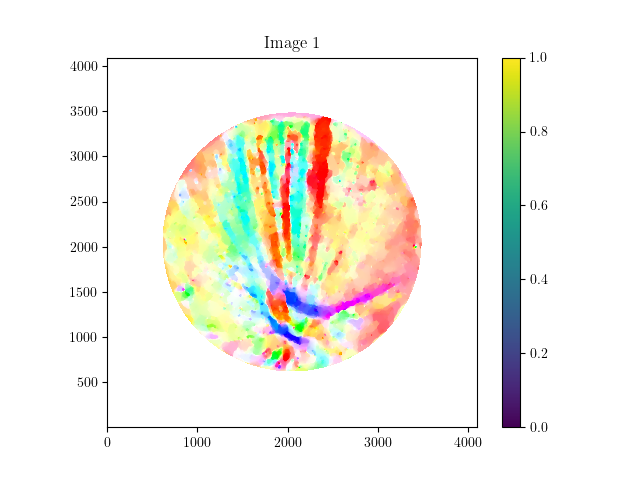

In [14]:
toggle_flow(flow, flow - flow_components, scale=5, mask=circular_mask(r=0.7), name="toggle_flow")

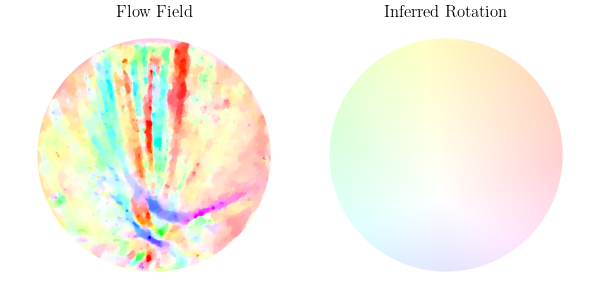

In [15]:
XLIMW = [450, 4096-450]
YLIMW = [450, 4096-450]

mask = circular_mask(r=0.7)

plt.close("rotational")
fig, axes = plt.subplots(1, 2, figsize=(6, 3), num="rotational")
ax1, ax2 = axes[0], axes[1]

ax1.imshow(flow.to_rgb(mask=mask, scale=8)[XLIMW[0]:XLIMW[1], YLIMW[0]:YLIMW[1]], origin="lower")
ax2.imshow(Flow(flow_components).to_rgb(mask=mask, scale=8)[XLIMW[0]:XLIMW[1], YLIMW[0]:YLIMW[1]], origin='lower')

ax1.set_title("Flow Field")
ax1.axis("off")
ax2.set_title("Inferred Rotation")
ax2.axis("off")

plt.tight_layout()
plt.show()

plt.savefig("flow.png", dpi=300)

## Showing frequency-dependence

In [25]:
flows = []

for i in range(8):
    image, psf, imwcs = data_1hour(i, order="time")
    sky = theoretical_sky(imwcs, psf, catalog="VLSSR", max_flux=10)
    image_processed, sky_processed = preprocess(image, sky, weight=1.5)
    flow_ = Flow.brox(image_processed, sky_processed, alpha=1.0, gamma=150, scale_factor=0.7)
    flows.append(flow_)

In [17]:
jnp.mean(jnp.linalg.norm(flows[0].offsets[4096//2-100:4096//2+100,4096//2-100:4096//2+100], axis=2))

Array(2.2469327, dtype=float32)

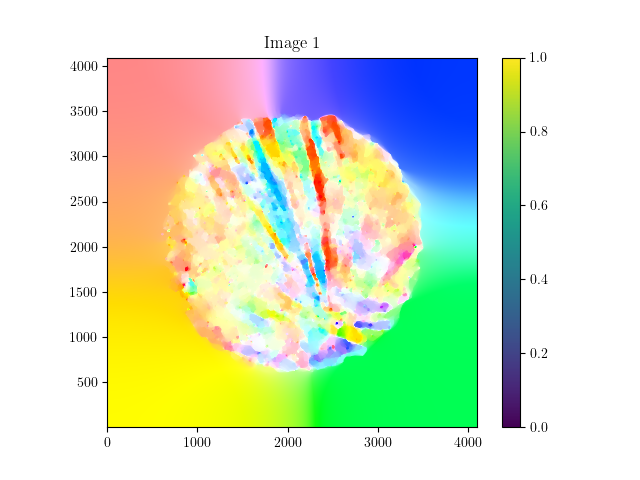

In [18]:
toggle_flow(flows[0], flows[3], scale=5)

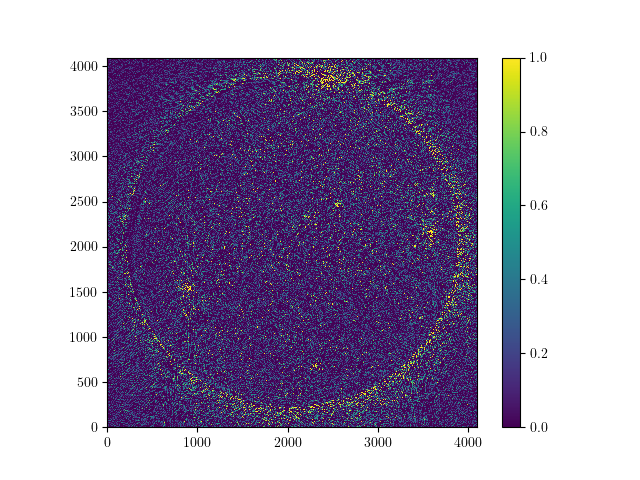

In [20]:
plot_image(normalize_high(image))

## Movie with flow field and TEC density

In [27]:
k_int = integrate_2d_fourier(flow.offsets, 1)

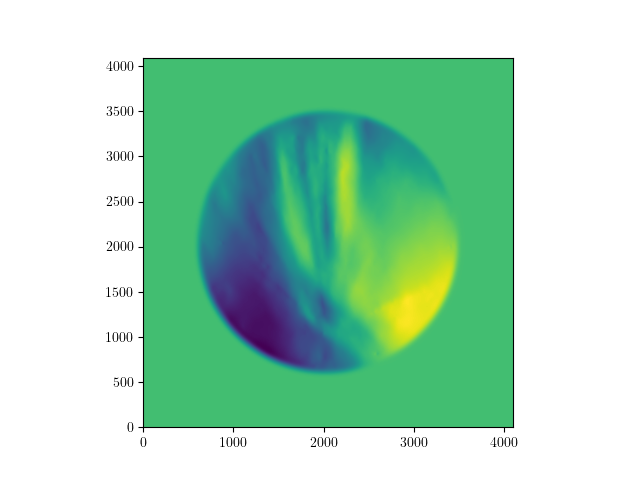

In [28]:
plt.close("tec")
plt.figure("tec")
plt.imshow(horizon_mask(k_int), origin='lower')
plt.show()

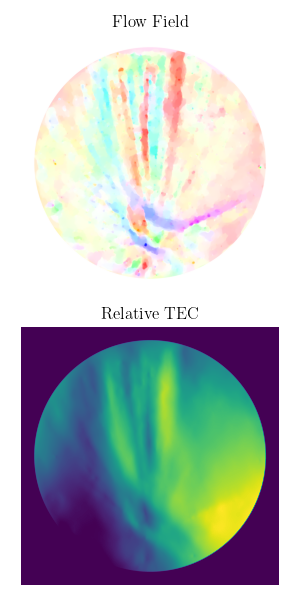

In [29]:
XLIMW = [450, 4096-450]
YLIMW = [450, 4096-450]

mask = circular_mask(r=0.7)

plt.close("flowtec")
# fig = plt.figure(figsize=(8, 4), num="flowtec")

# Create a GridSpec layout
# 1 row, 2 columns, with a width ratio of 2:1
# gs = gridspec.GridSpec(2, 2, width_ratios=[1, 1])

# Add subplots to the GridSpec
# ax1 = fig.add_subplot(gs[0])
# ax2 = fig.add_subplot(gs[1])
fig, axes = plt.subplots(2, 1, figsize=(3, 6), num="flowtec")
ax1, ax2 = axes[0], axes[1]

ax1.imshow(flow.to_rgb(mask=mask)[XLIMW[0]:XLIMW[1], YLIMW[0]:YLIMW[1]], origin="lower")
ax2.imshow((normalize(k_int) * mask)[XLIMW[0]:XLIMW[1], YLIMW[0]:YLIMW[1]], origin='lower')

ax1.set_title("Flow Field")
ax1.axis("off")
ax2.set_title("Relative TEC")
ax2.axis("off")

plt.tight_layout()
plt.show()

plt.savefig("flow.png", dpi=300)

In [30]:
jnp.quantile(k_int, 0.01), jnp.quantile(k_int, 0.99)

(Array(-1466.5004, dtype=float32), Array(1736.9465, dtype=float32))

In [31]:
def process(i):
    mask = circular_mask(r=0.7)
    
    image, psf, imwcs = data_1hour(i, order="freq")
    sky = theoretical_sky(imwcs, psf, catalog="VLSSR", max_flux=10)
    image_processed, sky_processed = preprocess(image, sky, weight=1.5)
    flow = Flow.brox(image_processed, sky_processed, alpha=1.2, gamma=150, scale_factor=0.7)
    
    k_int = integrate_2d_fourier(flow.offsets, 1)

    flow_vis = flow.to_rgb(mask, scale=5)
    density = ((k_int + 1000) / (1800)) * mask
    m = horizon_mask(k_int)
    print(jnp.quantile(m, 0.01).item(), jnp.quantile(m, 0.99).item())
    density = horizon_mask(normalize(horizon_mask(k_int)))

    xmin, xmax = 2100, 2400
    ymin, ymax = 1500, 1800

    preview_size = (4096//2, 4096//2, 3)
    
    xmin2, xmax2 = 450, 4096-450
    ymin2, ymax2 = 450, 4096-450

    image_grid = jnp.concat([
        jnp.concat([
            jax.image.resize(viridis(normalize_high(image))[xmax:xmin:-1,ymin:ymax,:], preview_size, method="linear"),
            jax.image.resize(viridis(normalize_high(sky))[xmax:xmin:-1,ymin:ymax,:], preview_size, method="linear"),
        ], axis=1),
        jnp.concat([
            jax.image.resize(flow_vis[xmax2:xmin2:-1,ymin2:ymax2,:], preview_size, method="linear"),
            jax.image.resize(viridis(density)[xmax2:xmin2:-1,ymin2:ymax2,:], preview_size, method="linear"),
        ], axis=1),
    ], axis=0)

    return image_grid

In [32]:
%time grid = process(37)

-1413.3583984375 187.954833984375
CPU times: user 2.08 s, sys: 277 ms, total: 2.35 s
Wall time: 3.45 s


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000002].


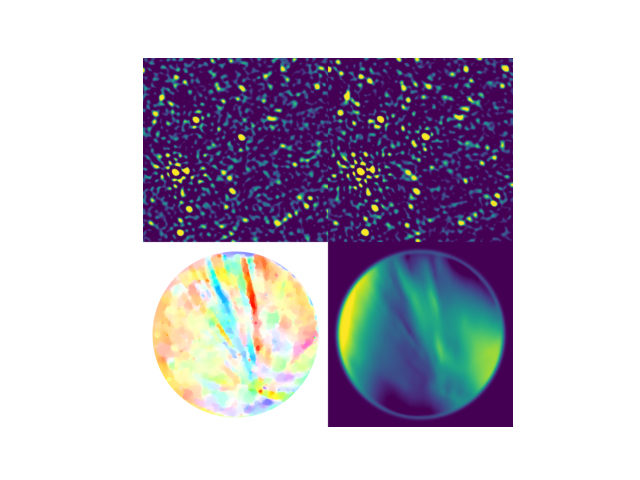

In [33]:
plt.close("frame0")
plt.figure(num="frame0")
plt.imshow(grid)
plt.axis("off")
plt.show()

In [34]:
from PIL import Image
import os
from tqdm import tqdm

def write_image(jax_array, frame_dir, frame=0):
    if not os.path.exists(frame_dir):
        os.mkdir(frame_dir)
    Image.fromarray(np.array(jnp.clip(jax_array, 0.0, 1.0) * 255.0).astype(np.uint8)).convert("RGB").save(f"{frame_dir}/{frame:03d}.png")
    
def make_movie(frame_dir, frames):
    for i, j in tqdm(enumerate(frames)):
        grid = process(j)
        write_image(grid, frame_dir, frame=i)

In [35]:
make_movie("/fastpool/zwhuang/workdir/flow", range(0, 72))

0it [00:00, ?it/s]

-1041.98193359375 192.60874938964844


1it [00:04,  4.47s/it]

-1081.55419921875 114.78486633300781


2it [00:08,  4.49s/it]

-1077.24462890625 248.2680206298828


... (135 outputs left out)

-1170.206787109375 308.6252136230469


71it [05:21,  4.52s/it]

-1711.078125 110.85806274414062


72it [05:25,  4.53s/it]


In [36]:
!ffmpeg -y -f image2 -framerate 6 -start_number 0 -i /fastpool/zwhuang/workdir/flow/%003d.png -vframes 36 /fastpool/zwhuang/workdir/flow_1hour_band_0.mp4
!ffmpeg -y -f image2 -framerate 6 -start_number 36 -i /fastpool/zwhuang/workdir/flow/%003d.png -vframes 36 /fastpool/zwhuang/workdir/flow_1hour_band_1.mp4

# !ffmpeg -y -f image2 -framerate 12 -i /fastpool/zwhuang/workdir/flow/%003d.png /fastpool/zwhuang/workdir/flow_1hour_band_2.mp4

ffmpeg version 6.1.1 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 11.2.0 (Anaconda gcc)
  configuration: --prefix=/fastpool/zwhuang/.conda/envs/lwa --cc=/croot/ffmpeg_1722024521393/_build_env/bin/x86_64-conda-linux-gnu-cc --ar=/croot/ffmpeg_1722024521393/_build_env/bin/x86_64-conda-linux-gnu-ar --nm=/croot/ffmpeg_1722024521393/_build_env/bin/x86_64-conda-linux-gnu-nm --ranlib=/croot/ffmpeg_1722024521393/_build_env/bin/x86_64-conda-linux-gnu-ranlib --strip=/croot/ffmpeg_1722024521393/_build_env/bin/x86_64-conda-linux-gnu-strip --disable-doc --enable-swresample --enable-swscale --enable-openssl --enable-libxml2 --enable-libtheora --enable-demuxer=dash --enable-postproc --enable-hardcoded-tables --enable-libfreetype --enable-libharfbuzz --enable-libfontconfig --enable-libdav1d --enable-zlib --enable-libaom --enable-pic --enable-shared --disable-static --disable-gpl --enable-version3 --disable-sdl2 --enable-libopenh264 --enable-libopus --enable-libmp3lame --enable-libopen

/fastpool/zwhuang/.conda/envs/lwa/lib/python3.11/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


Input #0, image2, from '/fastpool/zwhuang/workdir/flow/%003d.png':
  Duration: 00:00:18.00, start: 0.000000, bitrate: N/A
  Stream #0:0: Video: png, rgb24(pc, gbr/unknown/unknown), 4096x4096, 6 fps, 6 tbr, 6 tbn
Stream mapping:
  Stream #0:0 -> #0:0 (png (native) -> mpeg4 (native))
Press [q] to stop, [?] for help
Output #0, mp4, to '/fastpool/zwhuang/workdir/flow_1hour_band_0.mp4':
  Metadata:
    encoder         : Lavf60.16.100
  Stream #0:0: Video: mpeg4 (mp4v / 0x7634706D), yuv420p(tv, progressive), 4096x4096, q=2-31, 200 kb/s, 6 fps, 12288 tbn
    Metadata:
      encoder         : Lavc60.31.102 mpeg4
    Side data:
      cpb: bitrate max/min/avg: 0/0/200000 buffer size: 0 vbv_delay: N/A
[out#0/mp4 @ 0x1d45340] video:6367kB audio:0kB subtitle:0kB other streams:0kB global headers:0kB muxing overhead: 0.017378%
frame=   36 fps= 31 q=31.0 Lsize=    6368kB time=00:00:05.83 bitrate=8943.1kbits/s speed=4.97x    
ffmpeg version 6.1.1 Copyright (c) 2000-2023 the FFmpeg developers
  built wi